In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import os, glob, numpy as np, pandas as pd, matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

for p in glob.glob("/kaggle/input/datasets/satyaroopchatterjee/edge-ai-dataset/train.csv", recursive=True):
    if os.path.isfile(p): print(p, f"{os.path.getsize(p)/1e6:.1f} MB")

/kaggle/input/datasets/satyaroopchatterjee/edge-ai-dataset/train.csv 411.5 MB


In [2]:
CSV = glob.glob("/kaggle/input/datasets/satyaroopchatterjee/edge-ai-dataset/train.csv", recursive=True)[0]
df = pd.read_csv(CSV, header=None)
x = df.iloc[:, :187].values.astype("float32")
y = df.iloc[:, 187].values.astype(int)

print("shape:", df.shape, "| x:", x.shape, "| y:", y.shape)
print("NaNs:", np.isnan(x).sum(), "| label NaNs:", df.iloc[:, 187].isna().sum())
print("x range:", x.min(), x.max())
print("unique labels:", np.unique(y))

shape: (87554, 188) | x: (87554, 187) | y: (87554,)
NaNs: 0 | label NaNs: 0
x range: 0.0 1.0
unique labels: [0 1 2 3 4]


  class  count    pct
0     N  72471  82.77
1     S   2223   2.54
2     V   5788   6.61
3     F    641   0.73
4     Q   6431   7.35


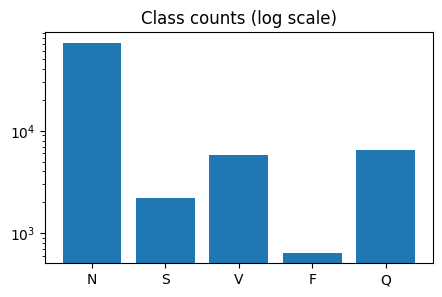

In [3]:
names = {0:"N", 1:"S", 2:"V", 3:"F", 4:"Q"}
cnt = np.bincount(y, minlength=5)
print(pd.DataFrame({"class":[names[i] for i in range(5)], "count":cnt, "pct":(cnt/cnt.sum()*100).round(2)}))

plt.figure(figsize=(5,3)); plt.bar([names[i] for i in range(5)], cnt); plt.yscale("log")
plt.title("Class counts (log scale)"); plt.show()

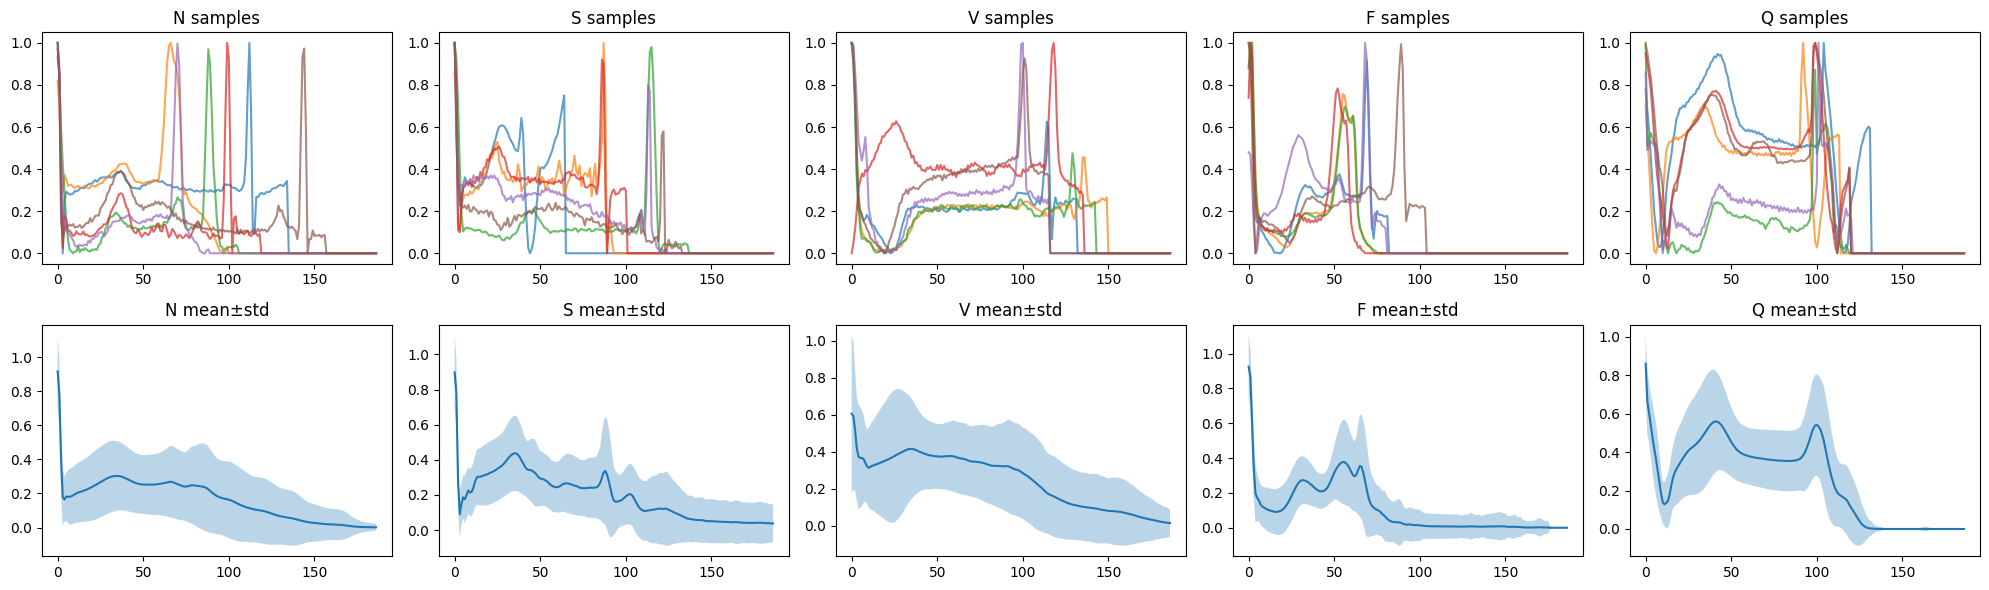

In [4]:
fig, ax = plt.subplots(2, 5, figsize=(20, 6))
rng = np.random.default_rng(0)
for c in range(5):
    idx = np.where(y == c)[0]
    for i in rng.choice(idx, 6, replace=False):
        ax[0, c].plot(x[i], alpha=.7)
    m, s = x[idx].mean(0), x[idx].std(0)
    ax[1, c].plot(m); ax[1, c].fill_between(range(187), m - s, m + s, alpha=.3)
    ax[0, c].set_title(f"{names[c]} samples"); ax[1, c].set_title(f"{names[c]} mean±std")
plt.tight_layout(); plt.show()

cls                    F        N        Q        S        V
length      mean  78.828  110.812  118.276  113.909  118.171
            std   13.923   27.183    9.745   39.241   34.910
peak_pos    mean   4.660   43.744   71.607   40.426   63.036
            std   18.019   49.018   43.715   49.144   54.232
start_level mean   0.588    0.488    0.630    0.438    0.501
            std    0.122    0.112    0.138    0.078    0.304
max         mean   1.000    1.000    1.000    0.992    1.000
            std    0.000    0.002    0.000    0.036    0.011
min         mean   0.000    0.000    0.000    0.001    0.000
            std    0.001    0.001    0.000    0.010    0.003
range       mean   1.000    1.000    1.000    0.991    1.000
            std    0.001    0.003    0.000    0.040    0.012


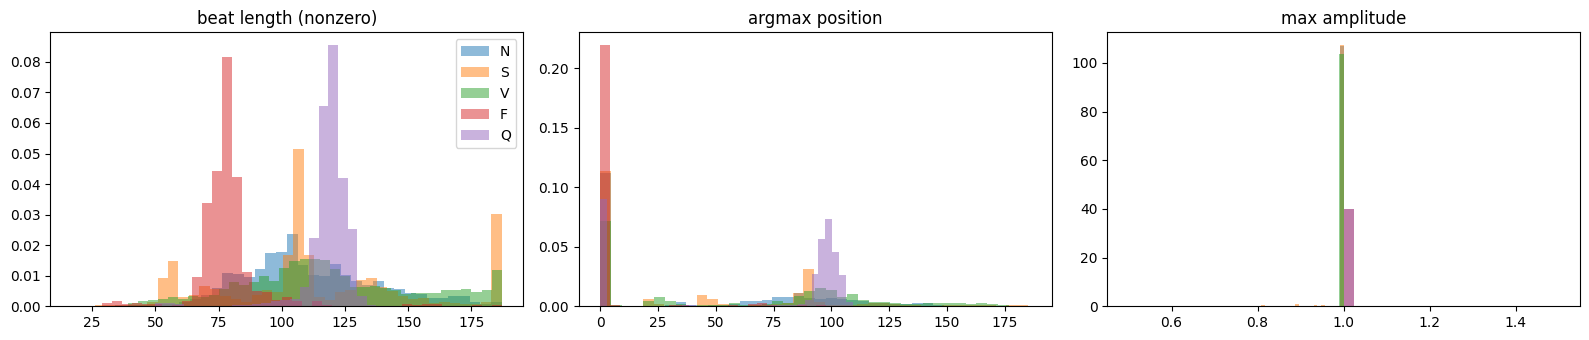

In [5]:
nz = x != 0
length = np.where(nz.any(1), 186 - np.argmax(nz[:, ::-1], axis=1) + 1, 0)
peak = x.argmax(1)
base_start = x[:, :5].mean(1)
amp = x.max(1) - x.min(1)

stats = pd.DataFrame({"cls":[names[i] for i in y], "length":length, "peak_pos":peak,
                      "start_level":base_start, "max":x.max(1), "min":x.min(1), "range":amp})
print(stats.groupby("cls").agg(["mean","std"]).round(3).T)

fig, ax = plt.subplots(1, 3, figsize=(16, 3.5))
for c in range(5):
    ax[0].hist(length[y==c], bins=40, alpha=.5, label=names[c], density=True)
    ax[1].hist(peak[y==c],   bins=40, alpha=.5, label=names[c], density=True)
    ax[2].hist(x[y==c].max(1), bins=40, alpha=.5, label=names[c], density=True)
ax[0].set_title("beat length (nonzero)"); ax[1].set_title("argmax position"); ax[2].set_title("max amplitude")
ax[0].legend(); plt.tight_layout(); plt.show()

In [6]:
from collections import defaultdict
keys = [row.tobytes() for row in x]
d = defaultdict(list)
for i, k in enumerate(keys): d[k].append(i)

dup_groups = [v for v in d.values() if len(v) > 1]
n_dup_rows = sum(len(v) - 1 for v in dup_groups)
conflict = sum(1 for v in dup_groups if len(set(y[v])) > 1)
print(f"exact duplicate rows: {n_dup_rows} ({n_dup_rows/len(x)*100:.2f}%) | groups: {len(dup_groups)}")
print(f"groups with conflicting labels: {conflict}")
print("duplicates by class:", pd.Series(y[[i for v in dup_groups for i in v[1:]]]).map(names).value_counts().to_dict())

exact duplicate rows: 0 (0.00%) | groups: 0
groups with conflicting labels: 0
duplicates by class: {}


In [7]:
from sklearn.neighbors import NearestNeighbors
sub = rng.choice(len(x), 20000, replace=False)
nn = NearestNeighbors(n_neighbors=2).fit(x[sub])
dist, ind = nn.kneighbors(x[sub])
d1 = dist[:, 1]
print("NN-distance percentiles (5,25,50,75,95):", np.percentile(d1, [5,25,50,75,95]).round(3))
print("fraction with NN dist < 0.1 :", (d1 < 0.1).mean().round(3))
print("NN has same label:", (y[sub] == y[sub][ind[:, 1]]).mean().round(4))

NN-distance percentiles (5,25,50,75,95): [0.174 0.267 0.39  0.592 1.123]
fraction with NN dist < 0.1 : 0.001
NN has same label: 0.968


In [8]:
# high-freq residual after a 5-pt moving average = noise estimate
k = np.ones(5) / 5
smooth = np.apply_along_axis(lambda r: np.convolve(r, k, mode="same"), 1, x[:5000])
noise_std = (x[:5000] - smooth)[:, 3:-3].std(1)
print("per-beat noise std percentiles (5,50,95):", np.percentile(noise_std, [5, 50, 95]).round(4))

# low-freq drift: mean of first 10 samples vs last nonzero 10 samples
end_level = np.array([x[i, max(length[i]-10, 0):length[i]].mean() if length[i] > 0 else 0 for i in range(5000)])
drift = end_level - x[:5000, :10].mean(1)
print("start→end drift percentiles (5,50,95):", np.percentile(drift, [5, 50, 95]).round(3))

per-beat noise std percentiles (5,50,95): [0.0228 0.044  0.0579]
start→end drift percentiles (5,50,95): [-0.318 -0.141  0.214]


In [9]:
# high-freq residual after a 5-pt moving average = noise estimate
k = np.ones(5) / 5
smooth = np.apply_along_axis(lambda r: np.convolve(r, k, mode="same"), 1, x[:5000])
noise_std = (x[:5000] - smooth)[:, 3:-3].std(1)
print("per-beat noise std percentiles (5,50,95):", np.percentile(noise_std, [5, 50, 95]).round(4))

# low-freq drift: mean of first 10 samples vs last nonzero 10 samples
end_level = np.array([x[i, max(length[i]-10, 0):length[i]].mean() if length[i] > 0 else 0 for i in range(5000)])
drift = end_level - x[:5000, :10].mean(1)
print("start→end drift percentiles (5,50,95):", np.percentile(drift, [5, 50, 95]).round(3))

per-beat noise std percentiles (5,50,95): [0.0228 0.044  0.0579]
start→end drift percentiles (5,50,95): [-0.318 -0.141  0.214]


In [10]:
import shutil
for f in ["edge_helpers.py", "check_submission.py"]:
    hits = glob.glob(f"/kaggle/input/**/{f}", recursive=True)
    print(f, "->", hits)
    if hits: shutil.copy(hits[0], "/kaggle/working/" + f)

print(open("/kaggle/input/datasets/satyaroopchatterjee/starter-kits/edge_helpers.py").read())

edge_helpers.py -> ['/kaggle/input/datasets/satyaroopchatterjee/starter-kits/edge_helpers.py']
check_submission.py -> ['/kaggle/input/datasets/satyaroopchatterjee/starter-kits/check_submission.py']
"""
Edge AI Challenge - helper functions for teams.

This file does NOT contain a model. Designing and training the model is
your job. These helpers only handle the fiddly parts: loading the data,
converting your Keras model to the required int8 TFLite format, and
measuring the int8 model the same way the organizers will.

Typical use inside your own train.py:

    from edge_helpers import load_csv, export_int8, evaluate_tflite
    from sklearn.model_selection import train_test_split

    x, y = load_csv("train.csv")
    x_tr, x_val, y_tr, y_val = train_test_split(
        x, y, test_size=0.15, stratify=y, random_state=42)

    model = ...            # build your own Keras model, input shape (187, 1)
    model.fit(x_tr[..., None], y_tr, ...)

    export_int8(model, x_tr, "model.tflite")
    

In [12]:
#Data and Split
import numpy as np, pandas as pd, glob, os, tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, classification_report, confusion_matrix

SEED = 42
tf.keras.utils.set_random_seed(SEED)
CSV = glob.glob("/kaggle/input/datasets/satyaroopchatterjee/edge-ai-dataset/train.csv", recursive=True)[0]
df = pd.read_csv(CSV, header=None)
X = df.iloc[:, :187].values.astype("float32")
Y = df.iloc[:, 187].values.astype("int64")

xtr, xva, ytr, yva = train_test_split(X, Y, test_size=0.15, stratify=Y, random_state=SEED)
print(xtr.shape, xva.shape, np.bincount(ytr), np.bincount(yva))

(74420, 187) (13134, 187) [61600  1889  4920   545  5466] [10871   334   868    96   965]


In [15]:
#data augmentation
def beat_len(x):
    nz = x > 0
    return np.where(nz.any(1), 187 - np.argmax(nz[:, ::-1], axis=1), 0)

def augment(x, rng):
    n = len(x); pos = np.arange(187)[None, :]
    valid = (pos < beat_len(x)[:, None]).astype("float32")
    whole = rng.random((n, 1)) < 0.5                       # perturb padded tail too, or only the beat
    mask = np.where(whole, 1.0, valid).astype("float32")
    gate = lambda p: (rng.random((n, 1)) < p).astype("float32")

    out = x * (1 + gate(0.7) * rng.uniform(-0.35, 0.25, (n, 1)))                 # amplitude change
    out = out + mask * gate(0.5) * rng.uniform(-0.1, 0.1, (n, 1))                # DC offset
    f, ph = rng.uniform(0.2, 1.5, (n, 1)), rng.uniform(0, 2*np.pi, (n, 1))
    out = out + mask * gate(0.6) * rng.uniform(0, 0.15, (n, 1)) * np.sin(2*np.pi*f*pos/187 + ph)  # baseline wander
    out = out + mask * gate(0.6) * rng.uniform(0, 0.05, (n, 1)) * rng.standard_normal(x.shape)    # sensor noise

    ren = rng.random((n, 1)) < 0.2                                               # hedge: organizers may re-normalize
    mn, mx = out.min(1, keepdims=True), out.max(1, keepdims=True)
    out = np.where(ren, (out - mn) / (mx - mn + 1e-6), out)
    clip01 = rng.random((n, 1)) < 0.5                                            # hedge: clipped to 0-1 or not
    out = np.where(clip01, np.clip(out, 0, 1), np.clip(out, -0.3, 1.5))
    return out.astype("float32")

rng = np.random.default_rng(SEED)
xva_aug = augment(xva, np.random.default_rng(123))   # fixed "hard" validation set

In [16]:
from tensorflow.keras import layers as L, Model

def build(w=(8, 16, 24, 32), ks=(7, 5, 5, 3), drop=0.2):
    inp = L.Input((187, 1)); x = inp
    for c, k in zip(w, ks):
        x = L.Conv1D(c, k, strides=2, padding="same", use_bias=False)(x)
        x = L.BatchNormalization()(x)
        x = L.ReLU(6.0)(x)
    x = L.Flatten()(x)
    x = L.Dropout(drop)(x)
    return Model(inp, L.Dense(5)(x))

model = build()
print("params:", model.count_params())

I0000 00:00:1791613946.766504      48 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791613946.770043      48 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


params: 7165


In [21]:
cw = {c: (len(ytr) / (5 * np.sum(ytr == c))) ** 0.5 for c in range(5)}
print("class weights:", {k: round(v, 2) for k, v in cw.items()})

def mf1(m, x, y):
    return f1_score(y, m.predict(x[..., None], batch_size=2048, verbose=0).argmax(1), average="macro")

ytronh = tf.keras.utils.to_categorical(ytr, num_classes=5)

cw = {c: (len(ytr) / (5 * np.sum(ytr == c))) ** 0.5 for c in range(5)}
print("class weights:", {k: round(v, 2) for k, v in cw.items()})

def mf1(m, x, y):
    return f1_score(y, m.predict(x[..., None], batch_size=2048, verbose=0).argmax(1),
                    average="macro")

ytr_oh = tf.keras.utils.to_categorical(ytr, num_classes=5)

EPOCHS, BS, LR0 = 40, 256, 2e-3

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LR0),
    loss=tf.keras.losses.CategoricalCrossentropy(from_logits=True, label_smoothing=0.05),
)

best = (-1, None)
for ep in range(EPOCHS):
    model.optimizer.learning_rate.assign(LR0 * 0.5 * (1 + np.cos(np.pi * ep / EPOCHS)))
    model.fit(augment(xtr, rng)[..., None], ytr_oh,      # one-hot labels here
              batch_size=BS, epochs=1, class_weight=cw, shuffle=True, verbose=0)
    a, b = mf1(model, xva, yva), mf1(model, xva_aug, yva)  # yva stays integer for f1_score
    if (a + b) / 2 > best[0]:
        best = ((a + b) / 2, model.get_weights())
    print(f"ep{ep:02d} clean {a:.4f} aug {b:.4f}")

model.set_weights(best[1])
print("best avg:", round(best[0], 4))


class weights: {0: np.float64(0.49), 1: np.float64(2.81), 2: np.float64(1.74), 3: np.float64(5.23), 4: np.float64(1.65)}
class weights: {0: np.float64(0.49), 1: np.float64(2.81), 2: np.float64(1.74), 3: np.float64(5.23), 4: np.float64(1.65)}
ep00 clean 0.8396 aug 0.8030
ep01 clean 0.8880 aug 0.8527
ep02 clean 0.8885 aug 0.8546
ep03 clean 0.8955 aug 0.8519
ep04 clean 0.9005 aug 0.8582
ep05 clean 0.8949 aug 0.8614
ep06 clean 0.9014 aug 0.8647
ep07 clean 0.8947 aug 0.8551
ep08 clean 0.9027 aug 0.8689
ep09 clean 0.8859 aug 0.8484
ep10 clean 0.8719 aug 0.8340
ep11 clean 0.8916 aug 0.8589
ep12 clean 0.9034 aug 0.8676
ep13 clean 0.8975 aug 0.8657
ep14 clean 0.8977 aug 0.8675
ep15 clean 0.8935 aug 0.8626
ep16 clean 0.9013 aug 0.8697
ep17 clean 0.8992 aug 0.8687
ep18 clean 0.8994 aug 0.8715
ep19 clean 0.9056 aug 0.8692
ep20 clean 0.9040 aug 0.8771
ep21 clean 0.9028 aug 0.8753
ep22 clean 0.8970 aug 0.8667
ep23 clean 0.9048 aug 0.8722
ep24 clean 0.9050 aug 0.8714
ep25 clean 0.9006 aug 0.8686
ep26

In [22]:
def to_int8(model, rep_x, path):
    def rep():
        for i in range(len(rep_x)): yield [rep_x[i:i+1, :, None].astype("float32")]
    c = tf.lite.TFLiteConverter.from_keras_model(model)
    c.optimizations = [tf.lite.Optimize.DEFAULT]
    c.representative_dataset = rep
    c.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
    c.inference_input_type = tf.int8; c.inference_output_type = tf.int8
    open(path, "wb").write(c.convert())

def eval_tflite(path, x, y):
    it = tf.lite.Interpreter(model_path=path); it.allocate_tensors()
    i, o = it.get_input_details()[0], it.get_output_details()[0]
    s, z = i["quantization"]
    q = np.clip(np.round(x / s + z), -128, 127).astype("int8")
    P, ties = [], 0
    for r in q:
        it.set_tensor(i["index"], r.reshape(1, 187, 1)); it.invoke()
        out = it.get_tensor(o["index"])[0]; P.append(out.argmax()); ties += (out == out.max()).sum() > 1
    return np.array(P), ties, (s, z)

# stratified representative set: clean + augmented, rare classes included
idx = np.concatenate([rng.choice(np.where(ytr == c)[0], min(500, (ytr == c).sum()), replace=False) for c in range(5)])
rep_x = np.concatenate([xtr[idx], augment(xtr[idx], rng)])
to_int8(model, rep_x, "model_baseline.tflite")
print("tflite size (KB):", os.path.getsize("model_baseline.tflite") / 1024)

for name, xs in [("clean", xva), ("aug", xva_aug)]:
    p, ties, qp = eval_tflite("model_baseline.tflite", xs, yva)
    print(f"\n== int8 on {name} val | macro-F1 {f1_score(yva, p, average='macro'):.4f} | ties {ties} | in scale/zp {qp}")
    print(classification_report(yva, p, target_names=list("NSVFQ"), digits=3))
    print(confusion_matrix(yva, p))

INFO:tensorflow:Assets written to: /tmp/tmpus9vo052/assets


INFO:tensorflow:Assets written to: /tmp/tmpus9vo052/assets


Saved artifact at '/tmp/tmpus9vo052'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 187, 1), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  134453379863504: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134453379864080: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134453379863888: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134453379864464: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134453379861584: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134453379864656: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134453379863696: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134453379865424: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134453379864272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134453379862352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134453379865040: Te

W0000 00:00:1791614715.953258      48 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1791614715.953282      48 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1791614715.964893      48 mlir_graph_optimization_pass.cc:437] MLIR V1 optimization pass is not enabled
fully_quantize: 0, inference_type: 6, input_inference_type: INT8, output_inference_type: INT8
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


tflite size (KB): 17.0234375

== int8 on clean val | macro-F1 0.9138 | ties 10 | in scale/zp (0.006491835694760084, -91)
              precision    recall  f1-score   support

           N      0.992     0.990     0.991     10871
           S      0.840     0.835     0.838       334
           V      0.959     0.965     0.962       868
           F      0.728     0.865     0.790        96
           Q      0.984     0.992     0.988       965

    accuracy                          0.983     13134
   macro avg      0.901     0.929     0.914     13134
weighted avg      0.984     0.983     0.983     13134

[[10758    52    24    22    15]
 [   54   279     1     0     0]
 [   19     1   838     9     1]
 [    5     0     8    83     0]
 [    5     0     3     0   957]]

== int8 on aug val | macro-F1 0.8805 | ties 7 | in scale/zp (0.006491835694760084, -91)
              precision    recall  f1-score   support

           N      0.988     0.986     0.987     10871
           S      0.808   

In [25]:
import glob, os, shutil, subprocess, sys

os.chdir("/kaggle/working")

for f in ["edge_helpers.py", "check_submission.py"]:
    # Searches recursively under /kaggle/input for the exact file name
    matches = glob.glob(f"/kaggle/input/**/{f}", recursive=True)
    if not matches:
        raise FileNotFoundError(f"Could not find {f} under /kaggle/input. Check your dataset path.")
    
    src = matches[0]
    dst = f"/kaggle/working/{f}"
    
    if os.path.exists(dst): 
        os.chmod(dst, 0o644)
    shutil.copyfile(src, dst)
    os.chmod(dst, 0o644)

r = subprocess.run(
    [sys.executable, "check_submission.py", "--model", "model_baseline.tflite", "--check-only"],
    capture_output=True, text=True
)
print(r.stdout)
print(r.stderr[-1500:])

=== FORMAT CHECK ===
{
  "format_ok": false,
  "problems": [
    "operators not on the allowed list: ['PACK', 'SHAPE', 'STRIDED_SLICE']"
  ],
  "file_kb": 17.02,
  "input": {
    "shape": [
      1,
      187,
      1
    ],
    "dtype": "int8",
    "quant": [
      0.006491835694760084,
      -91
    ]
  },
  "output": {
    "shape": [
      1,
      5
    ],
    "dtype": "int8"
  },
  "ops": [
    "CONV_2D",
    "EXPAND_DIMS",
    "FULLY_CONNECTED",
    "PACK",
    "RESHAPE",
    "SHAPE",
    "STRIDED_SLICE"
  ],
  "weights_kib_estimate": 7.07,
  "ops_outside_baseline_set": [
    "PACK",
    "SHAPE",
    "STRIDED_SLICE"
  ]
}
RESULT: FAIL

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
  

In [27]:
import sys, subprocess
sys.path.insert(0, "/kaggle/working")
from edge_helpers import export_int8
from tensorflow.keras import layers as L, Model

KS = (7, 5, 5, 3)

def build(w, batch=None, drop=0.2):
    inp = L.Input(batch_shape=(batch, 187, 1))
    x = inp
    for c, k in zip(w, KS):
        x = L.Conv1D(c, k, strides=2, padding="same", use_bias=False)(x)
        x = L.BatchNormalization()(x)
        x = L.ReLU()(x)
    feat = int(x.shape[1] * x.shape[2])           # static, e.g. 12*32 = 384
    x = L.Reshape((feat,))(x)                     # replaces Flatten -> no SHAPE/PACK/STRIDED_SLICE
    x = L.Dropout(drop)(x)
    return Model(inp, L.Dense(5)(x))

def make_export_model(m, w):
    e = build(w, batch=1)
    e.set_weights(m.get_weights())
    return e

def smooth_ce(eps=0.05):
    def loss(y_true, logits):
        y = tf.cast(tf.reshape(y_true, [-1]), tf.int32)
        oh = tf.one_hot(y, 5) * (1 - eps) + eps / 5
        return tf.nn.softmax_cross_entropy_with_logits(labels=oh, logits=logits)
    return loss

def macs(m):
    t = 0
    for l in m.layers:
        if isinstance(l, L.Conv1D):
            t += int(np.prod(l.output.shape[1:])) * l.kernel_size[0] * int(l.input.shape[-1])
        elif isinstance(l, L.Dense):
            t += int(l.input.shape[-1]) * l.units
    return t

def train(w, epochs=30, lr0=2e-3):
    tf.keras.utils.set_random_seed(SEED)
    m = build(w)
    m.compile(tf.keras.optimizers.Adam(lr0), smooth_ce(0.05))
    best = (-1, None)
    for ep in range(epochs):
        m.optimizer.learning_rate.assign(lr0 * 0.5 * (1 + np.cos(np.pi * ep / epochs)))
        m.fit(augment(xtr, rng)[..., None], ytr, batch_size=256, epochs=1, class_weight=cw, verbose=0)
        a, b = mf1(m, xva, yva), mf1(m, xva_aug, yva)
        if (a + b) / 2 > best[0]: best = ((a + b) / 2, m.get_weights())
    m.set_weights(best[1]); return m

def run_checker(path):
    r = subprocess.run([sys.executable, "/kaggle/working/check_submission.py", "--model", path, "--check-only"],
                       capture_output=True, text=True, cwd="/kaggle/working")
    txt = r.stdout
    return "PASS" if "RESULT: PASS" in txt else "FAIL", txt

def int8_scores(m, w, tag):
    path = f"{tag}.tflite"
    export_int8(make_export_model(m, w), rep_x, path, n_rep=len(rep_x))
    status, txt = run_checker(path)
    out = {"tag": tag, "params": m.count_params(), "MACs": macs(m),
           "KB": round(os.path.getsize(path) / 1024, 1), "checker": status}
    if status == "FAIL": print(txt)
    for nm, xs in [("clean", xva), ("aug", xva_aug)]:
        p, ties, _ = eval_tflite(path, xs, yva)
        out[f"F1_{nm}"] = round(f1_score(yva, p, average="macro"), 4)
        out[f"F1_{nm}_per"] = np.round(f1_score(yva, p, average=None), 3).tolist()
    return out

configs = {"tiny": (6, 12, 16, 24), "base": (8, 16, 24, 32), "wide": (12, 24, 32, 48)}
rows, models = [], {}
for tag, w in configs.items():
    models[tag] = train(w)
    rows.append(int8_scores(models[tag], w, tag)); print(rows[-1])
pd.DataFrame(rows)

INFO:tensorflow:Assets written to: /tmp/tmp3kt3qt28/assets


INFO:tensorflow:Assets written to: /tmp/tmp3kt3qt28/assets


Saved artifact at '/tmp/tmp3kt3qt28'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(1, 187, 1), dtype=tf.float32, name='keras_tensor_48')
Output Type:
  TensorSpec(shape=(1, 5), dtype=tf.float32, name=None)
Captures:
  134452746957072: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134452746960336: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134452746954576: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134452746954000: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134452746960528: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134452746955152: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134452254535184: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134452254538832: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134452746960720: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134452746955536: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134452254532112: Tenso

W0000 00:00:1791615395.201563      48 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1791615395.201591      48 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
fully_quantize: 0, inference_type: 6, input_inference_type: INT8, output_inference_type: INT8


saved tiny.tflite (10.11 KiB)
{'tag': 'tiny', 'params': 4191, 'MACs': 59172, 'KB': 10.1, 'checker': 'PASS', 'F1_clean': 0.8745, 'F1_clean_per': [0.985, 0.765, 0.922, 0.721, 0.979], 'F1_aug': 0.8554, 'F1_aug_per': [0.983, 0.735, 0.903, 0.682, 0.975]}
INFO:tensorflow:Assets written to: /tmp/tmpjqykvme4/assets


...

INFO:tensorflow:Assets written to: /tmp/tmpmyas30h7/assets


Saved artifact at '/tmp/tmpmyas30h7'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(1, 187, 1), dtype=tf.float32, name='keras_tensor_112')
Output Type:
  TensorSpec(shape=(1, 5), dtype=tf.float32, name=None)
Captures:
  134453600448592: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134449797857744: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134449797859280: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134455895210704: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134455824329872: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134449797860432: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134449797861776: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134449797873296: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134449797860624: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134449797862928: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134449797862544: Tens

W0000 00:00:1791615592.073847      48 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1791615592.073872      48 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
fully_quantize: 0, inference_type: 6, input_inference_type: INT8, output_inference_type: INT8


saved wide.tflite (20.39 KiB)
{'tag': 'wide', 'params': 13321, 'MACs': 225912, 'KB': 20.4, 'checker': 'PASS', 'F1_clean': 0.9098, 'F1_clean_per': [0.991, 0.839, 0.95, 0.781, 0.988], 'F1_aug': 0.8865, 'F1_aug_per': [0.988, 0.79, 0.935, 0.735, 0.985]}


,tag,params,MACs,KB,checker,F1_clean,F1_clean_per,F1_aug,F1_aug_per
0,tiny,4191,59172,10.1,PASS,0.8745,"[0.985, 0.765, 0.922, 0.721, 0.979]",0.8554,"[0.983, 0.735, 0.903, 0.682, 0.975]"
1,base,7165,110992,13.5,PASS,0.9018,"[0.989, 0.814, 0.943, 0.776, 0.987]",0.8850,"[0.987, 0.781, 0.925, 0.753, 0.979]"
2,wide,13321,225912,20.4,PASS,0.9098,"[0.991, 0.839, 0.95, 0.781, 0.988]",0.8865,"[0.988, 0.79, 0.935, 0.735, 0.985]"


## generic builder, SWA, distillation, sweep

In [28]:
from tensorflow.keras import layers as L, Model

def build2(spec, head="flat", batch=None, drop=0.2):
    inp = L.Input(batch_shape=(batch, 187, 1)); x = inp
    for c, k, s, p in spec:
        x = L.Conv1D(c, k, strides=s, padding="same", use_bias=False)(x)
        x = L.BatchNormalization()(x); x = L.ReLU()(x)
        if p: x = L.MaxPooling1D(2)(x)
    if head == "gap": x = L.GlobalAveragePooling1D()(x)
    else:             x = L.Reshape((int(x.shape[1] * x.shape[2]),))(x)   # static: no SHAPE/PACK ops
    return Model(inp, L.Dense(5)(L.Dropout(drop)(x)))

SPEC = {
  "base":   ([(8,7,2,0),(16,5,2,0),(24,5,2,0),(32,3,2,0)], "flat"),
  "sug":    ([(16,7,1,1),(24,5,1,1),(32,5,1,1),(48,3,1,1),(64,3,1,0)], "gap"),    # your architecture
  "sug_fl": ([(16,7,1,1),(24,5,1,1),(32,5,1,1),(48,3,1,1),(64,3,1,0)], "flat"),
  "teacher":([(32,7,1,1),(64,5,1,1),(96,5,1,1),(128,3,1,1),(128,3,1,0)], "flat"),
}
mk = lambda tag, batch=None: build2(*SPEC[tag][:1], head=SPEC[tag][1], batch=batch)

def kd_loss(T=3.0, a=0.5, eps=0.05):
    def loss(yt, logits):
        y = tf.cast(yt[:, 0], tf.int32)
        oh = tf.one_hot(y, 5) * (1 - eps) + eps / 5
        hard = tf.nn.softmax_cross_entropy_with_logits(labels=oh, logits=logits)
        soft = tf.nn.softmax_cross_entropy_with_logits(labels=yt[:, 1:], logits=logits / T) * T * T
        return (1 - a) * hard + a * soft
    return loss

def fit_model(tag, epochs=40, lr0=2e-3, swa_last=8, teacher=None, T=3.0, a=0.5, seed=SEED):
    tf.keras.utils.set_random_seed(seed)
    m = mk(tag)
    sw = np.array([cw[c] for c in ytr], "float32")
    m.compile(tf.keras.optimizers.Adam(lr0), kd_loss(T, a) if teacher is not None else smooth_ce(0.05))
    pool = []
    for ep in range(epochs):
        m.optimizer.learning_rate.assign(lr0 * 0.5 * (1 + np.cos(np.pi * ep / epochs)))
        xa = augment(xtr, rng)[..., None]
        if teacher is not None:
            soft = tf.nn.softmax(teacher.predict(xa, batch_size=4096, verbose=0) / T).numpy()
            yt = np.concatenate([ytr[:, None].astype("float32"), soft], 1)
        else:
            yt = ytr
        m.fit(xa, yt, batch_size=256, epochs=1, sample_weight=sw, verbose=0)
        if ep >= epochs - swa_last: pool.append(m.get_weights())
    m.set_weights([np.mean(w, 0) for w in zip(*pool)])      # SWA over the last epochs
    return m

def report(m, tag, name):
    e = mk(tag, batch=1); e.set_weights(m.get_weights())
    path = f"{name}.tflite"
    export_int8(e, rep_x, path, n_rep=len(rep_x))
    status, txt = run_checker(path)
    out = {"name": name, "params": m.count_params(), "MACs": macs(m),
           "KB": round(os.path.getsize(path) / 1024, 1), "checker": status}
    if "ops_outside_baseline_set" in txt:
        out["non_baseline_ops"] = txt.split('"ops_outside_baseline_set": ')[1].split("]")[0].replace("\n", "").replace(" ", "") + "]"
    for nm, xs in [("clean", xva), ("aug", xva_aug)]:
        p, _, _ = eval_tflite(path, xs, yva)
        out[f"F1_{nm}"] = round(f1_score(yva, p, average="macro"), 4)
        out[f"{nm}_per"] = np.round(f1_score(yva, p, average=None), 3).tolist()
    return out

# 1) float teacher (needs GPU; unconstrained, never exported)
teacher = fit_model("teacher", epochs=40)
print("teacher float  clean:", round(mf1(teacher, xva, yva), 4), " aug:", round(mf1(teacher, xva_aug, yva), 4))

# 2) students: plain vs distilled, plus your architecture variants
rows = []
rows.append(report(fit_model("base"),                 "base",   "base_swa"))
rows.append(report(fit_model("base", teacher=teacher), "base",   "base_kd"))
rows.append(report(fit_model("sug"),                  "sug",    "sug_gap"))
rows.append(report(fit_model("sug_fl"),               "sug_fl", "sug_flat"))
pd.set_option("display.max_colwidth", None); pd.DataFrame(rows)

2026-10-10 07:05:46.645966: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-10 07:05:46.859123: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


teacher float  clean: 0.9252  aug: 0.91
INFO:tensorflow:Assets written to: /tmp/tmp0jy3m_ji/assets


INFO:tensorflow:Assets written to: /tmp/tmp0jy3m_ji/assets


Saved artifact at '/tmp/tmp0jy3m_ji'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(1, 187, 1), dtype=tf.float32, name='keras_tensor_167')
Output Type:
  TensorSpec(shape=(1, 5), dtype=tf.float32, name=None)
Captures:
  134449792174800: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134449394736144: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134449394737296: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134449394729232: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134449394730000: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134449394739792: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134449394729424: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134449394739216: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134449394735760: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134449394737872: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134449394738448: Tens

W0000 00:00:1791616209.928892      48 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1791616209.928929      48 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
fully_quantize: 0, inference_type: 6, input_inference_type: INT8, output_inference_type: INT8


...

INFO:tensorflow:Assets written to: /tmp/tmpr4ph_8eg/assets


Saved artifact at '/tmp/tmpr4ph_8eg'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(1, 187, 1), dtype=tf.float32, name='keras_tensor_284')
Output Type:
  TensorSpec(shape=(1, 5), dtype=tf.float32, name=None)
Captures:
  134449098601104: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134449098600720: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134449098600336: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134449098600528: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134449098599376: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134449098600912: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134449098589392: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134449098599568: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134449098588816: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134449098590352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134449098598992: Tens

W0000 00:00:1791616594.178513      48 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1791616594.178550      48 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
fully_quantize: 0, inference_type: 6, input_inference_type: INT8, output_inference_type: INT8


saved sug_flat.tflite (34.01 KiB)


,name,params,MACs,KB,checker,non_baseline_ops,F1_clean,clean_per,F1_aug,aug_per
0,base_swa,7165,110992,13.6,PASS,[],0.8991,"[0.989, 0.823, 0.944, 0.752, 0.987]",0.8736,"[0.986, 0.786, 0.924, 0.691, 0.981]"
1,base_kd,7165,110992,13.6,PASS,[],0.9002,"[0.99, 0.825, 0.947, 0.75, 0.99]",0.8830,"[0.987, 0.783, 0.925, 0.737, 0.983]"
2,sug_gap,20757,583824,31.4,PASS,"[""MAX_POOL_2D""]",0.9094,"[0.991, 0.844, 0.96, 0.766, 0.986]",0.8814,"[0.988, 0.792, 0.941, 0.705, 0.982]"
3,sug_flat,23957,587024,34.0,PASS,"[""MAX_POOL_2D""]",0.9139,"[0.992, 0.87, 0.958, 0.761, 0.989]",0.8975,"[0.99, 0.828, 0.952, 0.733, 0.985]"


In [30]:
FINAL = "base"          # or "wide"
SPEC["wide"] = ([(12,7,2,0),(24,5,2,0),(32,5,2,0),(48,3,2,0)], "flat")

# two seeds, keep the better one on (clean + aug) val
cands = [fit_model(FINAL, epochs=50, teacher=teacher, seed=s) for s in (42, 7)]
scores = [(mf1(m, xva, yva) + mf1(m, xva_aug, yva)) / 2 for m in cands]
best = cands[int(np.argmax(scores))]; print("seed scores:", np.round(scores, 4))

# batch-1 export model with static Reshape
exp = mk(FINAL, batch=1); exp.set_weights(best.get_weights())
export_int8(exp, rep_x, "model.tflite", n_rep=len(rep_x))

from edge_helpers import evaluate_tflite
f1_clean = evaluate_tflite("model.tflite", xva, yva)    # official metric, writes validation.txt
p, ties, qp = eval_tflite("model.tflite", xva_aug, yva)
f1_aug = f1_score(yva, p, average="macro")
print("aug val macro-F1:", round(f1_aug, 4), "| input scale/zp:", qp)
status, txt = run_checker("model.tflite"); print(txt[:1500])

seed scores: [0.89   0.8869]
INFO:tensorflow:Assets written to: /tmp/tmpdtkd0c2u/assets


INFO:tensorflow:Assets written to: /tmp/tmpdtkd0c2u/assets


Saved artifact at '/tmp/tmpdtkd0c2u'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(1, 187, 1), dtype=tf.float32, name='keras_tensor_387')
Output Type:
  TensorSpec(shape=(1, 5), dtype=tf.float32, name=None)
Captures:
  134449080787088: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134449080791696: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134449080790544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134449080793808: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134449080779600: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134449080788048: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134449080791120: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134449080779984: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134449080779024: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134449080787856: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134449080788816: Tens

W0000 00:00:1791617559.780050      48 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1791617559.780097      48 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
fully_quantize: 0, inference_type: 6, input_inference_type: INT8, output_inference_type: INT8


saved model.tflite (13.57 KiB)
Validation macro-F1 (int8 model): 0.9021
Per-class F1 [N,S,V,F,Q]: [0.9895, 0.8282, 0.9417, 0.7628, 0.9881]
Model file size: 13.57 KiB (model.tflite)

              precision    recall  f1-score   support

           0      0.991     0.988     0.990     10871
           1      0.849     0.808     0.828       334
           2      0.934     0.949     0.942       868
           3      0.689     0.854     0.763        96
           4      0.986     0.991     0.988       965

    accuracy                          0.980     13134
   macro avg      0.890     0.918     0.902     13134
weighted avg      0.981     0.980     0.980     13134

wrote validation.txt
aug val macro-F1: 0.88 | input scale/zp: (0.006491835694760084, -91)
=== FORMAT CHECK ===
{
  "format_ok": true,
  "problems": [],
  "file_kb": 13.57,
  "input": {
    "shape": [
      1,
      187,
      1
    ],
    "dtype": "int8",
    "quant": [
      0.006491835694760084,
      -91
    ]
  },
  "output

In [32]:
import shutil

def tune_bias(m, xva, yva, shrink=0.5, clip=0.7, seed=999):
    rs = np.random.default_rng(seed)
    idx = rs.permutation(len(xva)); A, B = idx[:len(idx)//2], idx[len(idx)//2:]
    def mkset(ii):
        return (np.concatenate([xva[ii], augment(xva[ii], rs), augment(xva[ii], rs)]), np.tile(yva[ii], 3))
    (xa, ya), (xb, yb) = mkset(A), mkset(B)
    la = m.predict(xa[..., None], batch_size=4096, verbose=0)
    lb = m.predict(xb[..., None], batch_size=4096, verbose=0)
    f = lambda lg, y, d: f1_score(y, (lg + d).argmax(1), average="macro")
    d, grid = np.zeros(5), np.arange(-1.5, 1.51, 0.1)
    for _ in range(2):
        for c in (1, 2, 3, 4):
            sc = [f(la, ya, np.where(np.arange(5) == c, g, d)) for g in grid]
            d[c] = grid[int(np.argmax(sc))]
    d = np.clip(d * shrink, -clip, clip)
    before, after = f(lb, yb, np.zeros(5)), f(lb, yb, d)
    print(f"offsets {np.round(d, 2)} | held-out F1 {before:.4f} -> {after:.4f}")
    return d if after - before > 0.003 else np.zeros(5)

old_avg = (f1_clean + f1_aug) / 2
shutil.copy("model.tflite", "model_nobias.tflite")        # safety copy
delta = tune_bias(best, xva, yva)

if np.any(delta != 0):
    w = best.get_weights(); w[-1] = w[-1] + delta          # last array = Dense bias
    exp2 = mk(FINAL, batch=1); exp2.set_weights(w)
    export_int8(exp2, rep_x, "model.tflite", n_rep=len(rep_x))
    p, _, _ = eval_tflite("model.tflite", xva, yva);     new_clean = f1_score(yva, p, average="macro")
    p, _, qp2 = eval_tflite("model.tflite", xva_aug, yva); new_aug = f1_score(yva, p, average="macro")
    print(f"before: clean {f1_clean:.4f} aug {f1_aug:.4f} | after: clean {new_clean:.4f} aug {new_aug:.4f}")
    if (new_clean + new_aug) / 2 > old_avg:
        f1_clean, f1_aug, qp = new_clean, new_aug, qp2
        print("KEEPING the bias-tuned model")
    else:
        shutil.copy("model_nobias.tflite", "model.tflite")
        print("Bias did not help -> restored the original model")
else:
    print("No bias change needed; keeping the original model")

# re-run official evaluation so validation.txt matches the model that is now model.tflite
evaluate_tflite("model.tflite", xva, yva)
status, txt = run_checker("model.tflite"); print(status); print(txt[:600])

offsets [ 0.   -0.4  -0.3  -0.65 -0.35] | held-out F1 0.8708 -> 0.8799
INFO:tensorflow:Assets written to: /tmp/tmpcjggezpl/assets


INFO:tensorflow:Assets written to: /tmp/tmpcjggezpl/assets


Saved artifact at '/tmp/tmpcjggezpl'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(1, 187, 1), dtype=tf.float32, name='keras_tensor_451')
Output Type:
  TensorSpec(shape=(1, 5), dtype=tf.float32, name=None)
Captures:
  134455733755664: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134449070113232: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134449070121680: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134455895210704: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134453600448592: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134449070125328: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134449069727120: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134449069727888: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134449069729808: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134449069732112: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134449069722704: Tens

W0000 00:00:1791617878.744276      48 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1791617878.744314      48 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
fully_quantize: 0, inference_type: 6, input_inference_type: INT8, output_inference_type: INT8


saved model.tflite (13.61 KiB)
before: clean 0.8997 aug 0.8763 | after: clean 0.9032 aug 0.8832
KEEPING the bias-tuned model
Validation macro-F1 (int8 model): 0.9032
Per-class F1 [N,S,V,F,Q]: [0.9896, 0.8078, 0.9431, 0.7861, 0.9896]
Model file size: 13.61 KiB (model.tflite)

              precision    recall  f1-score   support

           0      0.988     0.992     0.990     10871
           1      0.886     0.743     0.808       334
           2      0.941     0.945     0.943       868
           3      0.752     0.823     0.786        96
           4      0.990     0.990     0.990       965

    accuracy                          0.981     13134
   macro avg      0.911     0.898     0.903     13134
weighted avg      0.980     0.981     0.980     13134

wrote validation.txt
PASS
=== FORMAT CHECK ===
{
  "format_ok": true,
  "problems": [],
  "file_kb": 13.61,
  "input": {
    "shape": [
      1,
      187,
      1
    ],
    "dtype": "int8",
    "quant": [
      0.006491835694760084,


In [33]:
import os
os.makedirs("/kaggle/working/sub/stm32", exist_ok=True)

In [34]:
%%writefile /kaggle/working/sub/stm32/ecg_pipeline.hpp
#pragma once
#pragma once
#include <cstdint>

extern "C" {
void ecg_init();                    // call once after MX_* init
void ecg_on_adc_sample(uint16_t s); // call from HAL_ADC_ConvCpltCallback (1 kHz)
void ecg_poll();                    // call from the main loop
}

Writing /kaggle/working/sub/stm32/ecg_pipeline.hpp


In [35]:
%%writefile /kaggle/working/sub/stm32/ecg_pipeline.hpp
#pragma once
#include "ecg_pipeline.hpp"
#include "main.h"
#include "network.h"          // X-CUBE-AI generated
#include "network_data.h"
#include <cmath>
#include <cstdio>
#include <cstring>
#include <algorithm>

// ---------- constants to set ----------
static constexpr float   INPUT_SCALE = 0.006491835f;  // <- paste qp scale printed after the final training
static constexpr int32_t INPUT_ZP    = -91;           // <- paste qp zero-point
static constexpr int     OVERSAMPLE  = 8;             // 1 kHz -> 125 Hz
static constexpr int     N_SAMPLES   = 187;
static constexpr int     TAIL_MARGIN = 8;             // samples kept after the next R-peak (tune)
static constexpr int     MIN_RR      = 38;            // 0.3 s  (>200 bpm rejected)
static constexpr int     REFRACTORY  = 25;            // 0.2 s
static constexpr int     RING        = 512;           // ~4 s of 125 Hz samples (power of 2)
static constexpr float   HP_ALPHA    = 0.9755f;       // ~0.5 Hz high-pass at 125 Hz
// --------------------------------------

static const char CLS[5] = {'N', 'S', 'V', 'F', 'Q'};

// 1) ISR side: boxcar decimation (adds anti-alias averaging) --> 125 Hz sample queue
static volatile uint16_t q_buf[64];
static volatile uint8_t  q_head = 0, q_tail = 0;
static uint32_t acc = 0; static uint8_t acc_n = 0;

extern "C" void ecg_on_adc_sample(uint16_t s) {
    acc += s;
    if (++acc_n == OVERSAMPLE) {
        q_buf[q_head & 63] = (uint16_t)(acc / OVERSAMPLE);
        q_head++; acc = 0; acc_n = 0;
    }
}

// 2) Filtering + R-peak detection state
static float    ring[RING];
static uint32_t n_idx = 0;                  // absolute 125 Hz sample counter
static float    hp_y = 0, hp_xprev = 0;
static float    peak_est = 0;               // running estimate of R amplitude
static float    s1 = 0, s2 = 0;             // previous two filtered samples
static int64_t  last_peak = -1000, prev_peak = -1;   // absolute indices
static int64_t  emit_at = -1, emit_start = -1, emit_end = -1;

// 3) Neural network
static ai_handle network = AI_HANDLE_NULL;
AI_ALIGNED(32) static ai_u8 activations[AI_NETWORK_DATA_ACTIVATIONS_SIZE];
static ai_buffer *ai_in, *ai_out;

extern "C" void ecg_init() {
    ai_network_params params = AI_NETWORK_PARAMS_INIT(
        AI_NETWORK_DATA_WEIGHTS(ai_network_data_weights_get()),
        AI_NETWORK_DATA_ACTIVATIONS(activations));
    ai_network_create(&network, AI_NETWORK_DATA_CONFIG);
    ai_network_init(network, &params);
    ai_in  = ai_network_inputs_get(network, nullptr);
    ai_out = ai_network_outputs_get(network, nullptr);

    CoreDebug->DEMCR |= CoreDebug_DEMCR_TRCENA_Msk;   // cycle counter for latency
    DWT->CYCCNT = 0; DWT->CTRL |= DWT_CTRL_CYCCNTENA_Msk;
}

static inline float at(int64_t abs_idx) { return ring[abs_idx & (RING - 1)]; }

static void classify(int64_t start, int64_t end) {   // window [start, end)
    int len = (int)(end - start);
    if (len < MIN_RR) return;
    if (len > N_SAMPLES) len = N_SAMPLES;

    float mn = 1e9f, mx = -1e9f;
    for (int i = 0; i < len; i++) { float v = at(start + i); mn = std::min(mn, v); mx = std::max(mx, v); }
    float rng = mx - mn; if (rng < 1e-6f) return;

    int8_t* in = (int8_t*)ai_in[0].data;
    for (int i = 0; i < N_SAMPLES; i++) {
        float x = (i < len) ? (at(start + i) - mn) / rng : 0.0f;      // 0..1, zero padded like the dataset
        int32_t q = (int32_t)lroundf(x / INPUT_SCALE) + INPUT_ZP;
        in[i] = (int8_t)std::min<int32_t>(127, std::max<int32_t>(-128, q));
    }

    uint32_t t0 = DWT->CYCCNT;
    ai_network_run(network, &ai_in[0], &ai_out[0]);
    uint32_t cyc = DWT->CYCCNT - t0;

    const int8_t* o = (const int8_t*)ai_out[0].data;
    int best = 0; for (int k = 1; k < 5; k++) if (o[k] > o[best]) best = k;
    printf("beat class %c  logits [%d %d %d %d %d]  %lu us\r\n", CLS[best],
           o[0], o[1], o[2], o[3], o[4], (unsigned long)(cyc / (SystemCoreClock / 1000000)));
}

static void process(float raw) {
    // high-pass (baseline wander removal): y[n] = a*(y[n-1] + x[n] - x[n-1])
    hp_y = HP_ALPHA * (hp_y + raw - hp_xprev); hp_xprev = raw;
    float f = hp_y;
    ring[n_idx & (RING - 1)] = f;

    // local-maximum R detector on s1 (previous sample), adaptive threshold
    if (n_idx >= 2) {
        float thr = (peak_est > 0) ? 0.5f * peak_est : 1e9f;
        bool is_peak = (s1 > s2) && (s1 >= f) && (s1 > thr) && ((int64_t)n_idx - 1 - last_peak > REFRACTORY);
        if (peak_est == 0 && n_idx > 250 ) {            // bootstrap: learn amplitude from first ~2 s
            float m = 0; for (int i = 0; i < 250; i++) m = std::max(m, at((int64_t)n_idx - i));
            peak_est = m;
        }
        if (is_peak) {
            int64_t p = (int64_t)n_idx - 1;
            peak_est = 0.875f * peak_est + 0.125f * s1;
            if (last_peak >= 0 && p - last_peak <= (N_SAMPLES - TAIL_MARGIN) && p - last_peak >= MIN_RR) {
                emit_start = last_peak; emit_end = p + TAIL_MARGIN; emit_at = emit_end;   // wait for the tail
            }
            prev_peak = last_peak; last_peak = p;
        }
    }
    s2 = s1; s1 = f; n_idx++;

    if (emit_at >= 0 && (int64_t)n_idx >= emit_at) {      // tail now available
        classify(emit_start, emit_end);
        emit_at = -1;
    }
}

extern "C" void ecg_poll() {
    while (q_tail != q_head) {
        uint16_t s = q_buf[q_tail & 63]; q_tail++;
        process((float)s / 4095.0f);
    }
}

Overwriting /kaggle/working/sub/stm32/ecg_pipeline.hpp


In [37]:
import re
s, z = qp                      # input scale and zero-point of the FINAL model
p = "/kaggle/working/sub/stm32/ecg_pipeline.hpp"
t = open(p).read()
t = re.sub(r"INPUT_SCALE\s*=\s*[0-9.eE+-]+f", f"INPUT_SCALE = {s:.9g}f", t)
t = re.sub(r"INPUT_ZP\s*=\s*-?\d+",          f"INPUT_ZP    = {int(z)}", t)
open(p, "w").write(t)
print([l for l in t.splitlines() if "INPUT_SCALE" in l or "INPUT_ZP" in l][:2])

['static constexpr float   INPUT_SCALE = 0.00649183569f;  // <- paste qp scale printed after the final training', 'static constexpr int32_t INPUT_ZP    = -91;           // <- paste qp zero-point']


In [38]:
import shutil, os
params, mac = best.count_params(), macs(best)
kb = os.path.getsize("model.tflite") / 1024
bias_line = "per-class logit bias offsets tuned on a held-out half of validation and folded into the Dense bias." if np.any(delta != 0) and (f1_clean, f1_aug) != (None, None) else "per-class bias tuning tested; not needed."

os.makedirs("sub", exist_ok=True)
open("sub/note.md", "w").write(f"""# Edge AI Challenge: technical note

**Model:** 4-layer strided Conv1D (Conv1D+BN+ReLU, stride 2, no pooling) -> static Reshape -> Dense(5), int8 logits output.
{params} params, ~{mac//1000}k MACs, {kb:.1f} KiB file. Ops: CONV_2D, RESHAPE, FULLY_CONNECTED (checker: {status}).

**Preprocessing:** none outside the graph; the first conv learns filtering. Input quantised with the model's own
scale/zero-point; calibration set mixes clean and augmented beats of all 5 classes.

**Class imbalance:** sqrt-inverse-frequency class weights, label smoothing 0.05, fresh augmentation each epoch,
macro-F1 tracked on clean and augmented validation.

**Augmentation (from train.csv only):** amplitude scaling, DC offset, sinusoidal baseline wander, Gaussian noise,
random re-normalisation and clipping. No time shifts (beats start at the R-peak; length is a class cue).

**Optimisation:** strided convs instead of pooling (fewer MACs, no MAX_POOL op); Flatten-style head to keep timing
information (GAP was worse); plain ReLU; no softmax; static reshape (avoids SHAPE/PACK/STRIDED_SLICE ops);
knowledge distillation from a larger float teacher trained on train.csv only; SWA over last 8 epochs;
best of 2 seeds; {bias_line}

**Results (int8):** val macro-F1 clean {f1_clean:.4f}, augmented {f1_aug:.4f}. Hidden score is expected to be lower
(no patient split available).

**STM32 sensor code (bonus):** stm32/ecg_pipeline.{{hpp,cpp}}: AD8232 -> ADC1 at 1 kHz triggered by TIM6, decimated to 125 Hz,
baseline high-pass, adaptive R-peak detection, R-to-R beat windowing, per-beat min-max, zero padding to 187 samples,
int8 quantisation with the model's scale/zero-point, X-CUBE-AI inference and DWT-based latency printout.
""")

open("sub/team.txt", "w").write("Team name: <LAL HARPIC>\nMembers: <Sourish Dutta, Satyaroop Chattopadhyay>\nContact: <9143075971>\n")   # <-- EDIT THIS
for f in ["model.tflite", "validation.txt"]: shutil.copy(f, "sub/")
print(sorted(os.listdir("sub")), os.listdir("sub/stm32"))

['model.tflite', 'note.md', 'stm32', 'team.txt', 'validation.txt'] ['ecg_pipeline.hpp']
